# Traffic-AI — Model Comparison

This notebook uses the project's backend model-comparison pipeline so the notebook and Analytics dashboard evaluate the same models on the same features and chronological train/test split.

**Models:** Linear Regression, Random Forest, XGBoost  
**Selection metric:** Lowest MAE  
**Note:** Run this notebook from the project environment with the dataset and backend dependencies installed.

In [5]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the Traffic-AI project root, even if the notebook is opened from its Notebooks folder.
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        path for path in (current, *current.parents)
        if (path / "backend" / "model_comparison.py").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate backend/model_comparison.py. "
        "Open this notebook inside your Traffic-AI project."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\Sanat\OneDrive\Documents\MCA\Github Projects\Traffic_AI\Traffic-AI


## 1. Recompute model comparison

In [6]:
from backend.model_comparison import get_comparison

# Recompute instead of using the saved comparison cache.
comparison = get_comparison(recompute=True)
evaluation = comparison["evaluation"]

print("Target:", evaluation["target"])
print("Number of features:", len(evaluation["features"]))
print("Features:", evaluation["features"])
print("Training rows:", evaluation["train_rows"])
print("Testing rows:", evaluation["test_rows"])
print("Training date range:", evaluation["train_range"])
print("Testing date range:", evaluation["test_range"])
print("Split:", evaluation["split"])

Target: Vehicles
Number of features: 13
Features: ['Junction', 'hour', 'day', 'month', 'weekday', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_24', 'lag_168', 'roll_mean_3', 'roll_mean_24']
Training rows: 35908
Testing rows: 11540
Training date range: ['2015-11-08 00:00:00', '2017-03-02 18:00:00']
Testing date range: ['2017-03-02 19:00:00', '2017-06-30 23:00:00']
Split: chronological, earlier 80% of timestamps train / later 20% test, all junctions


## 2. Compare model metrics

Lower MAE and RMSE are better; higher R² is better.

In [7]:
results_df = pd.DataFrame(comparison["models"]).rename(
    columns={
        "name": "Model",
        "mae": "MAE",
        "rmse": "RMSE",
        "r2": "R²",
    }
)

results_df = results_df.sort_values("MAE").reset_index(drop=True)
display(
    results_df.style.format({
        "MAE": "{:.3f}",
        "RMSE": "{:.3f}",
        "R²": "{:.3f}",
    })
)

print(f"Best model by MAE: {comparison['best_model']}")

,Model,MAE,RMSE,R²
0,XGBoost,2.741,4.376,0.973
1,Random Forest,2.958,4.802,0.968
2,Linear Regression,3.118,4.772,0.968


Best model by MAE: XGBoost


## 3. Visualize the comparison

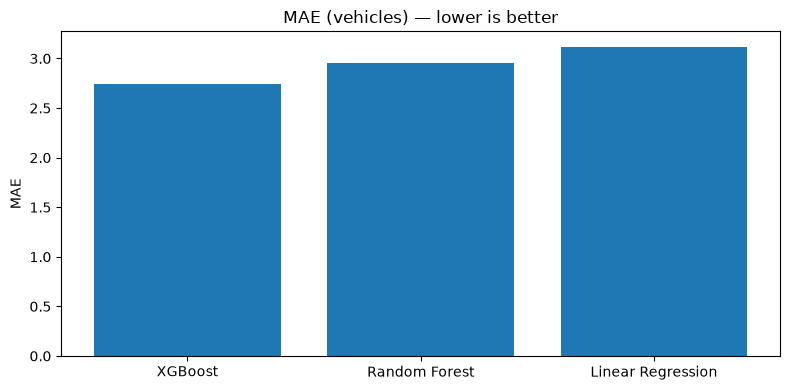

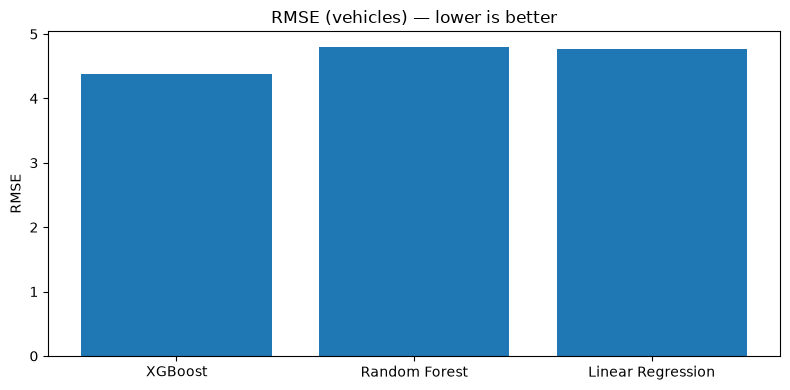

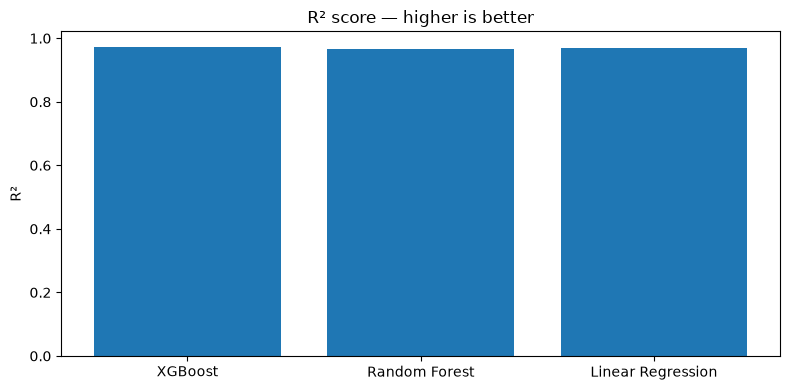

In [8]:
metrics = [
    ("MAE", "MAE (vehicles) — lower is better"),
    ("RMSE", "RMSE (vehicles) — lower is better"),
    ("R²", "R² score — higher is better"),
]

for column, title in metrics:
    plt.figure(figsize=(8, 4))
    plt.bar(results_df["Model"], results_df[column])
    plt.title(title)
    plt.ylabel(column)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 4. Interpretation

The best model is selected by the lowest MAE calculated on the same held-out chronological test set. Results may change if the dataset or model configuration changes. This notebook intentionally calls the backend comparison pipeline rather than maintaining a separate implementation, helping prevent metric mismatches with the dashboard.